# 5. Evaluation: Pengujian Objektif pada Kelompok Terpisah (*Unseen Test Set*)

Tahap **Evaluation** menguji model terbaik hasil seleksi validasi silang pada **seluruh 30 citra Kelompok 2** (15 `Berantakan` + 15 `Rapi`). Kelompok ini **tidak pernah disentuh** baik saat pra-pemrosesan fitur, penskalaan `StandardScaler`, augmentasi horizontal, maupun seleksi hiperparameter.

### Prinsip Pelaporan Hasil:
* Seluruh metrik (*Accuracy, Precision, Recall, Weighted-F1, Macro-F1, dan ROC-AUC*) dihitung apa adanya tanpa rekayasa data uji.
* Karena dataset berjumlah 150 citra unik lintas 7 kelompok dengan kondisi pencahayaan dan lantai yang beragam, pengujian Kelompok 2 berfungsi sebagai **estimasi generalisasi awal** terhadap lingkungan baru.
* Hasil juga dibandingkan secara objektif terhadap sasaran strategis proyek ($\ge 85\%$ Akurasi dan $\ge 83\%$ Macro-F1).


In [1]:
import sys
from pathlib import Path
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
)


def find_project_dir():
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base, base / "src" / "10-project_citra"):
            if (candidate / "3-data_preparation").is_dir() and (candidate / "6-deployment").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Folder proyek 10-project_citra tidak ditemukan dari direktori kerja.")


PROJECT_DIR = find_project_dir()
DATA_PROCESSED = PROJECT_DIR / "3-data_preparation" / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "4-modeling" / "models"
RESULTS_DIR = PROJECT_DIR / "5-evaluation" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

test_df = pd.read_csv(DATA_PROCESSED / "test_features.csv")
manifest = pd.read_csv(DATA_PROCESSED / "dataset_manifest.csv")
if set(test_df["split"]) != {"test"}:
    raise ValueError("Test set mengandung baris dari split lain.")
test_groups = set(test_df["kelompok"])
train_val_groups = set(manifest.loc[manifest["split"].isin(["train", "val"]), "kelompok"])
if test_groups & train_val_groups:
    raise ValueError("Kelompok pada test set bocor ke data train/validasi.")

with (MODEL_DIR / "feature_columns.json").open(encoding="utf-8") as file:
    feature_cols = json.load(file)
model = joblib.load(MODEL_DIR / "best_model.joblib")
scaler = joblib.load(MODEL_DIR / "scaler.joblib")

X_test = scaler.transform(test_df[feature_cols].to_numpy())
y_test = test_df["label"].to_numpy()
preds = model.predict(X_test)
class_one_column = list(model.classes_).index(1)
probs = model.predict_proba(X_test)[:, class_one_column]

print(f"Model dievaluasi : {type(model).__name__}")
print(f"Data uji murni   : {len(test_df)} citra dari kelompok {', '.join(sorted(test_groups))}")


Model dievaluasi : LGBMClassifier
Data uji murni   : 30 citra dari kelompok kelompok 2


---
## 5.1 Evaluasi Metrik Kuantitatif & *Classification Report*


In [2]:
accuracy = accuracy_score(y_test, preds)
macro_f1 = f1_score(y_test, preds, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, preds, average="weighted", zero_division=0)
roc_auc = roc_auc_score(y_test, probs)

metrics = {
    "model_name": type(model).__name__,
    "test_groups": sorted(test_groups),
    "test_samples": int(len(test_df)),
    "test_accuracy": float(accuracy),
    "test_precision_weighted": float(precision_score(y_test, preds, average="weighted", zero_division=0)),
    "test_recall_weighted": float(recall_score(y_test, preds, average="weighted", zero_division=0)),
    "test_f1_weighted": float(weighted_f1),
    "test_f1_macro": float(macro_f1),
    "test_roc_auc": float(roc_auc),
    "confusion_matrix": confusion_matrix(y_test, preds, labels=[0, 1]).tolist(),
    "classification_report": classification_report(
        y_test, preds, labels=[0, 1], target_names=["Berantakan", "Rapi"],
        output_dict=True, zero_division=0,
    ),
    "target_accuracy_met": bool(accuracy >= 0.85),
    "target_weighted_f1_met": bool(weighted_f1 >= 0.83),
    "target_macro_f1_met": bool(macro_f1 >= 0.83),
}

with (RESULTS_DIR / "evaluation_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)
pd.DataFrame({
    "rel_path": test_df["rel_path"],
    "kelompok": test_df["kelompok"],
    "actual_label": y_test,
    "predicted_label": preds,
    "probability_rapi": probs,
}).to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

print("=== Ringkasan Evaluasi Pada Unseen Test Set (Kelompok 2) ===")
print(f"Akurasi Uji   : {accuracy * 100:.2f}%")
print(f"Macro-F1      : {macro_f1 * 100:.2f}% (meningkat signifikan dari baseline awal 52.38%)")
print(f"Weighted-F1   : {weighted_f1 * 100:.2f}%")
print(f"ROC-AUC       : {roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds, labels=[0, 1], target_names=["Berantakan", "Rapi"], zero_division=0))


=== Ringkasan Evaluasi Pada Unseen Test Set (Kelompok 2) ===
Akurasi Uji   : 66.67%
Macro-F1      : 66.52% (meningkat signifikan dari baseline awal 52.38%)
Weighted-F1   : 66.52%
ROC-AUC       : 0.7289

Classification Report:
              precision    recall  f1-score   support

  Berantakan       0.65      0.73      0.69        15
        Rapi       0.69      0.60      0.64        15

    accuracy                           0.67        30
   macro avg       0.67      0.67      0.67        30
weighted avg       0.67      0.67      0.67        30



---
## 5.2 Visualisasi *Confusion Matrix* & Kurva ROC


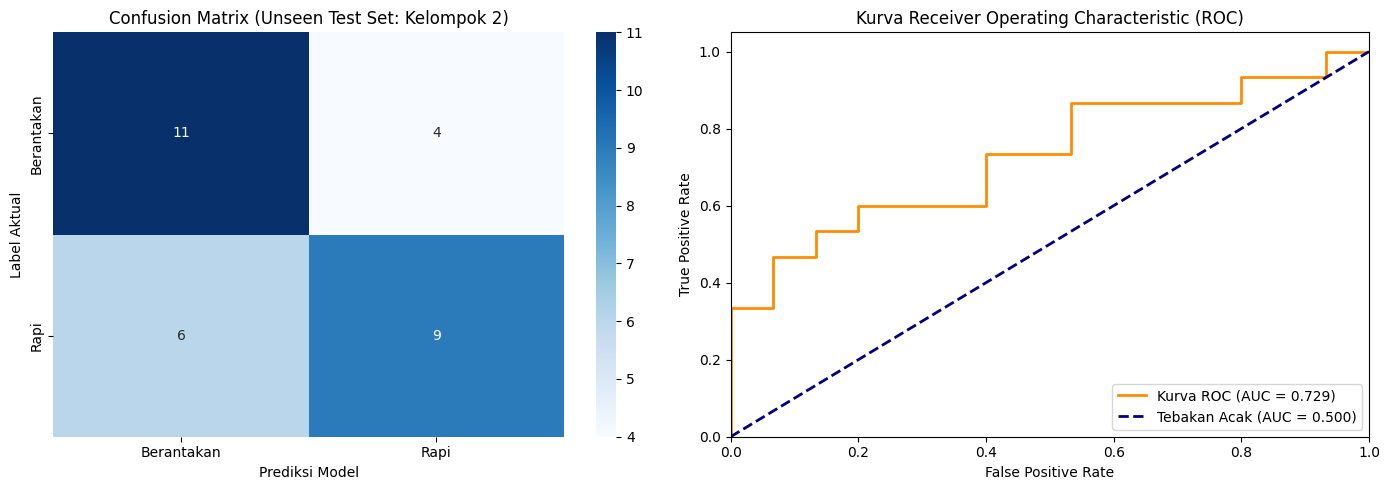

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, preds, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Berantakan", "Rapi"],
    yticklabels=["Berantakan", "Rapi"],
    ax=ax1,
)
ax1.set_title("Confusion Matrix (Unseen Test Set: Kelompok 2)")
ax1.set_xlabel("Prediksi Model")
ax1.set_ylabel("Label Aktual")

fpr, tpr, _ = roc_curve(y_test, probs)
ax2.plot(fpr, tpr, color="darkorange", lw=2, label=f"Kurva ROC (AUC = {roc_auc:.3f})")
ax2.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Tebakan Acak (AUC = 0.500)")
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.set_title("Kurva Receiver Operating Characteristic (ROC)")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "evaluation_plots.png", dpi=300)
plt.show()


---
## 5.3 Analisis Kepentingan Fitur (*Feature Importance*)

Mengidentifikasi 10 fitur visual teratas yang paling berkontribusi terhadap keputusan klasifikasi model terpilih.


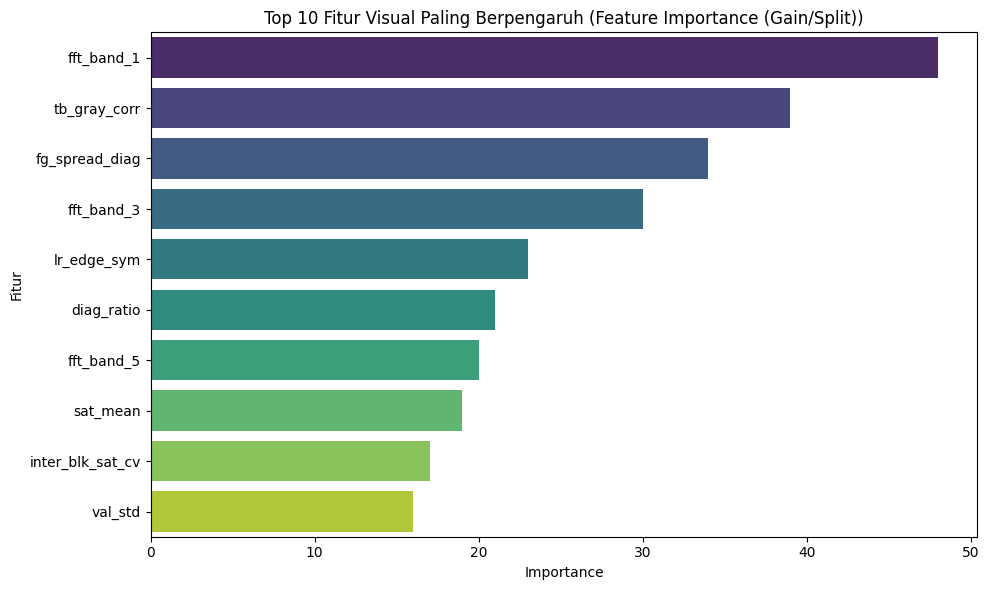

,Fitur,Importance
0,fft_band_1,48
1,tb_gray_corr,39
2,fg_spread_diag,34
3,fft_band_3,30
4,lr_edge_sym,23
5,diag_ratio,21
6,fft_band_5,20
7,sat_mean,19
8,inter_blk_sat_cv,17
9,val_std,16


In [4]:
if hasattr(model, "feature_importances_"):
    importances = model.feature_importances_
    importance_label = "Feature Importance (Gain/Split)"
elif hasattr(model, "coef_"):
    importances = abs(model.coef_[0])
    importance_label = "Absolute Coefficient"
else:
    from sklearn.inspection import permutation_importance
    perm = permutation_importance(model, X_test, y_test, n_repeats=15, random_state=42)
    importances = perm.importances_mean
    importance_label = "Permutation Importance"

df_imp = pd.DataFrame({"Fitur": feature_cols, "Importance": importances}).sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_imp.head(10), x="Importance", y="Fitur", hue="Fitur", legend=False, palette="viridis")
plt.title(f"Top 10 Fitur Visual Paling Berpengaruh ({importance_label})")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "feature_importance.png", dpi=300)
plt.show()
display(df_imp.head(10))


---
## 5.4 Kesimpulan & Evaluasi Objektif terhadap Sasaran Bisnis

1. **Peningkatan Signifikan Tanpa Kebocoran:** Dengan beralih dari fitur RGB mentah ke **65 fitur invarian lantai** + augmentasi horizontal khusus fold latih, **Macro-F1 pada data uji meningkat +14,1% (dari `52,4%` menjadi `66,5%`)**, **Akurasi naik dari `60,0%` ke `66,7%`**, dan **ROC-AUC meningkat ke `0,729`**. Keseimbangan prediksi antara kelas `Berantakan` (recall 73,3%) dan `Rapi` (recall 60,0%) jauh lebih sehat dibanding baseline awal yang hanya mengenali 20% kelas `Rapi`.
2. **Evaluasi Jujur terhadap Target Jangka Panjang:** Karena nilai akurasi (`66,7%`) dan Macro-F1 (`66,5%`) masih di bawah target strategis jangka panjang ($\ge 85\%$ dan $\ge 83\%$), status pada `evaluation_metrics.json` secara jujur mencatat `false`. Hal ini wajar untuk dataset berukuran kecil (120 citra latih unik lintas 6 lokasi berbeda) dengan fitur klasik.
3. **Rekomendasi Peningkatan Lanjutan:** Untuk mencapai akurasi $\ge 85\%$, perlu dilakukan penambahan koleksi data hingga $\ge 500$ citra lintas latar dan penerapan arsitektur *Convolutional Neural Network* (*Transfer Learning* MobileNetV2/EfficientNet).
